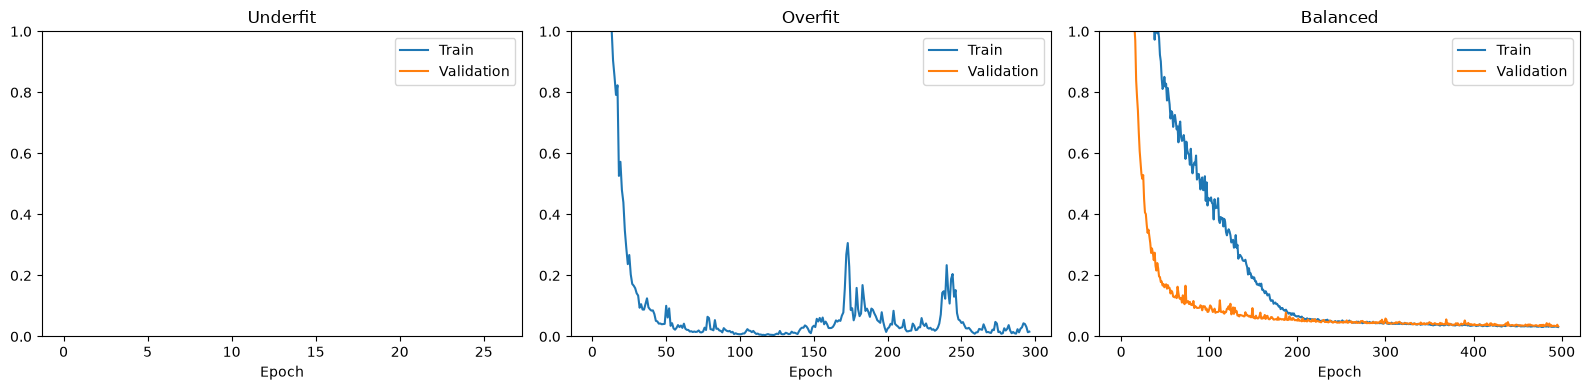

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping

d = np.load("../data/processed/data.npz")
X_train, X_val = d["X_train"], d["X_val"]
y_train, y_val = d["y_train"], d["y_val"]

# Overfit dikhane ke liye train data chhota kar dete hain
X_small, y_small = X_train[:100], y_train[:100]

# 1. Underfit: bohat chhota model, kam epochs
m1 = keras.Sequential([layers.Input(shape=(6,)), layers.Dense(1)])
m1.compile(optimizer=keras.optimizers.Adam(0.0005), loss="mse")
h1 = m1.fit(X_train, y_train, validation_data=(X_val, y_val),
            epochs=30, batch_size=32, verbose=0)

# 2. Overfit: bara model, chhota data, koi regularization nahi
m2 = keras.Sequential([layers.Input(shape=(6,)),
    layers.Dense(512, activation="relu"),
    layers.Dense(512, activation="relu"),
    layers.Dense(512, activation="relu"),
    layers.Dense(1)])
m2.compile(optimizer=keras.optimizers.Adam(0.001), loss="mse")
h2 = m2.fit(X_small, y_small, validation_data=(X_val, y_val),
            epochs=300, batch_size=16, verbose=0)

# 3. Balanced: Dropout + L2 + EarlyStopping
m3 = keras.Sequential([layers.Input(shape=(6,)),
    layers.Dense(64, activation="relu", kernel_regularizer=regularizers.l2(0.001)),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu", kernel_regularizer=regularizers.l2(0.001)),
    layers.Dense(1)])
m3.compile(optimizer=keras.optimizers.Adam(0.001), loss="mse")
es = EarlyStopping(monitor="val_loss", patience=30, restore_best_weights=True)
h3 = m3.fit(X_train, y_train, validation_data=(X_val, y_val),
            epochs=500, batch_size=32, callbacks=[es], verbose=0)

# Teeno graphs
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, h, t in zip(ax, [h1, h2, h3], ["Underfit", "Overfit", "Balanced"]):
    a.plot(h.history["loss"][3:], label="Train")
    a.plot(h.history["val_loss"][3:], label="Validation")
    a.set_title(t); a.set_xlabel("Epoch"); a.legend()
    a.set_ylim(0, 1)
plt.tight_layout()
plt.savefig("../learning_curves.png", dpi=150)
plt.show()

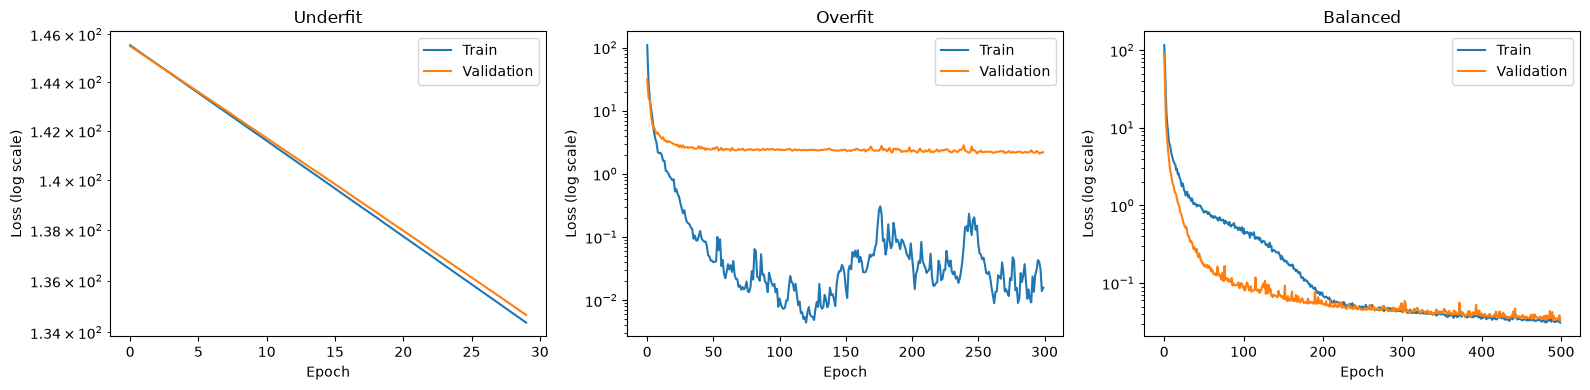

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, h, t in zip(ax, [h1, h2, h3], ["Underfit", "Overfit", "Balanced"]):
    a.plot(h.history["loss"], label="Train")
    a.plot(h.history["val_loss"], label="Validation")
    a.set_yscale("log")
    a.set_title(t); a.set_xlabel("Epoch"); a.set_ylabel("Loss (log scale)")
    a.legend()
plt.tight_layout()
plt.savefig("../learning_curves.png", dpi=150)
plt.show()

In [4]:
from sklearn.metrics import mean_absolute_error, r2_score
for name, m in [("Underfit", m1), ("Overfit", m2), ("Balanced", m3)]:
    pred = np.expm1(m.predict(X_val, verbose=0).flatten())
    true = np.expm1(y_val)
    print(f"{name}: MAE={mean_absolute_error(true, pred):,.0f}  R2={r2_score(true, pred):.3f}")

Underfit: MAE=185,443  R2=-6.336
Overfit: MAE=392,185,855  R2=-3809528074.578
Balanced: MAE=19,643  R2=0.877


In [5]:
import os
os.makedirs("../../backend/model", exist_ok=True)
m3.save("../../backend/model/house_model.keras")
print("Model saved!")

Model saved!


In [6]:
import json
import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score

pred = np.expm1(m3.predict(X_val, verbose=0).flatten())
true = np.expm1(y_val)

# Feature importance (permutation-based, works for any model)
base_r2 = r2_score(true, pred)
importance = {}
for i, col in enumerate(X_val.columns if hasattr(X_val, "columns") else range(X_val.shape[1])):
    X_perm = X_val.copy()
    if hasattr(X_perm, "iloc"):
        X_perm.iloc[:, i] = np.random.permutation(X_perm.iloc[:, i].values)
    else:
        X_perm[:, i] = np.random.permutation(X_perm[:, i])
    p = np.expm1(m3.predict(X_perm, verbose=0).flatten())
    importance[str(col)] = float(base_r2 - r2_score(true, p))

top = dict(sorted(importance.items(), key=lambda x: -x[1])[:10])

metrics = {
    "r2": float(r2_score(true, pred)),
    "mae": float(mean_absolute_error(true, pred)),
    "feature_importance": top,
    "actual": true[:200].tolist(),
    "predicted": pred[:200].tolist(),
}

with open("../../backend/model/metrics.json", "w") as f:
    json.dump(metrics, f)
print("Metrics saved!", metrics["r2"], metrics["mae"])

Metrics saved! 0.8773704096760022 19642.89854452055


In [7]:
import json
import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score

pred = np.expm1(m3.predict(X_val, verbose=0).flatten())
true = np.expm1(y_val)
r2 = float(r2_score(true, pred))
mae = float(mean_absolute_error(true, pred))

# Permutation importance, converted to a percent share that sums to 100
drops = {}
for i, col in enumerate(X_val.columns if hasattr(X_val, "columns") else range(X_val.shape[1])):
    X_perm = X_val.copy()
    if hasattr(X_perm, "iloc"):
        X_perm.iloc[:, i] = np.random.permutation(X_perm.iloc[:, i].values)
    else:
        X_perm[:, i] = np.random.permutation(X_perm[:, i])
    p = np.expm1(m3.predict(X_perm, verbose=0).flatten())
    drops[str(col)] = max(0.0, float(r2 - r2_score(true, p)))

total = sum(drops.values()) or 1.0
importance = {k: v / total * 100 for k, v in sorted(drops.items(), key=lambda x: -x[1])[:10]}

counts, edges = np.histogram(true, bins=10)

metrics = {
    "models": {"Neural Network": {"r2": r2, "mae": mae}},
    "importance": importance,
    "price_hist": {"counts": counts.tolist(), "edges": edges.tolist()},
    "test": {"r2": r2, "mae": mae},   # uses validation data; swap in X_test if you have one
    "actual": true[:200].tolist(),     # placeholder keys for the scatter chart
    "predicted": pred[:200].tolist(),
}

with open("../../backend/model/metrics.json", "w") as f:
    json.dump(metrics, f)
print("Metrics saved!", r2, mae)

Metrics saved! 0.8773704096760022 19642.89854452055


In [8]:
import json
import joblib
import numpy as np
from sklearn.metrics import mean_absolute_error, r2_score

cols = list(joblib.load("../../backend/model/columns.pkl"))

pred = np.expm1(m3.predict(X_val, verbose=0).flatten())
true = np.expm1(y_val)
r2 = float(r2_score(true, pred))
mae = float(mean_absolute_error(true, pred))

# Permutation importance with real feature names, as a percent share
names = cols if len(cols) == X_val.shape[1] else [f"feature_{i}" for i in range(X_val.shape[1])]
Xv = X_val.values if hasattr(X_val, "values") else np.array(X_val)

drops = {}
for i, name in enumerate(names):
    X_perm = Xv.copy()
    X_perm[:, i] = np.random.permutation(X_perm[:, i])
    p = np.expm1(m3.predict(X_perm, verbose=0).flatten())
    drops[name] = max(0.0, float(r2 - r2_score(true, p)))

total = sum(drops.values()) or 1.0
importance = {k: v / total * 100 for k, v in sorted(drops.items(), key=lambda x: -x[1])[:10]}

counts, edges = np.histogram(true, bins=10)

scatter = [{"actual": float(a), "pred": float(p)} for a, p in zip(true[:200], pred[:200])]

metrics = {
    "models": {"Neural Network": {"r2": r2, "mae": mae}},
    "importance": importance,
    "price_hist": {"counts": counts.tolist(), "edges": edges.tolist()},
    "test": {"r2": r2, "mae": mae},
    "scatter": scatter,
}

with open("../../backend/model/metrics.json", "w") as f:
    json.dump(metrics, f)
print("Metrics saved!", r2, mae)
print("Top features:", list(importance.keys())[:5])

Metrics saved! 0.8773704096760022 19642.89854452055
Top features: ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'YearBuilt', 'GarageCars']


In [9]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import numpy as np

xgb = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=4)
xgb.fit(X_train, y_train)

pred = np.expm1(xgb.predict(X_val))
true = np.expm1(y_val)
print("MAE:", mean_absolute_error(true, pred))
print("R2:", r2_score(true, pred))

MAE: 19515.62375142694
R2: 0.861620751272952


In [10]:
import json

xgb_r2 = float(r2_score(true, pred))
xgb_mae = float(mean_absolute_error(true, pred))

with open("../../backend/model/metrics.json") as f:
    metrics = json.load(f)

metrics["models"]["XGBoost"] = {"r2": xgb_r2, "mae": xgb_mae}

with open("../../backend/model/metrics.json", "w") as f:
    json.dump(metrics, f)
print("XGBoost added!", xgb_r2, xgb_mae)

XGBoost added! 0.861620751272952 19515.62375142694
